In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("combined_tremor_dataset.csv")


In [ ]:
df.columns

Index(['task', 'timestamp', 'x', 'y', 'z', 'label'], dtype='object')

In [ ]:
df1 = df.drop('timestamp', axis =1)

In [ ]:
df1.columns

Index(['task', 'x', 'y', 'z', 'label'], dtype='object')

In [ ]:
df1.task.unique()

array([0, 1, 2, 3, 4])

In [ ]:
df1.label.unique()

array([0, 1, 2])

In [ ]:
df1 = df1[df1['label'] != 0]

In [ ]:
df1.label.unique()

array([1, 2])

In [ ]:
#df1['label'] = df1['label'].replace(0, 1)

In [ ]:
df1.isnull().sum()

,0
task,0
x,0
y,0
z,0
label,0


In [ ]:
rows_to_drop1 = df1[df1['task'] == 4].index
df11= df1.drop(rows_to_drop1)

In [ ]:
df11.task.unique()

array([0, 1, 2, 3])

In [ ]:
df11.label.unique()

array([1, 2])

In [ ]:
df0 = df11.loc[df11['task'] == 0]

In [ ]:
df0.shape

(6676, 5)

In [ ]:
df0.task.unique()

array([0])

In [ ]:
df1 = df11.loc[df11['task'] == 1]

In [ ]:
df2 = df11.loc[df11['task'] == 2]

In [ ]:
df3 = df11.loc[df11['task'] == 3]

In [ ]:
df1.task.unique()

array([1])

In [ ]:
df2.task.unique()

array([2])

In [ ]:
df3.task.unique()

array([3])

In [ ]:
df1.shape

(6675, 5)

In [ ]:
df2.shape

(6492, 5)

In [ ]:
df3.shape

(6795, 5)

In [ ]:
df0.to_csv('task0.csv')

In [ ]:
df1.to_csv('task1.csv')

In [ ]:
df2.to_csv('task2.csv')

In [ ]:
df3.to_csv('task3.csv')

In [ ]:
df0.label.unique()

array([1, 2])

In [ ]:
df0.label.value_counts()

,count
label,
1,4461
2,2215


<Figure size 1200x600 with 0 Axes>

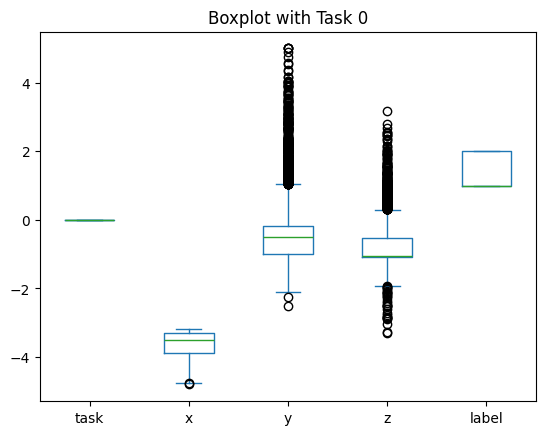

In [ ]:
plt.figure(figsize=(12,6))
df0.plot.box(title='Boxplot with Task 0')
plt.show()

<Figure size 1200x600 with 0 Axes>

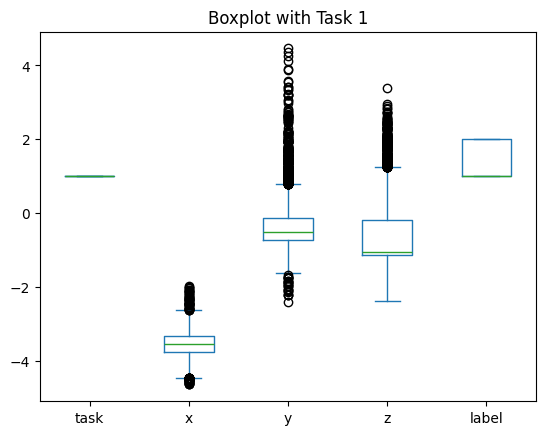

In [ ]:
plt.figure(figsize=(12,6))
df1.plot.box(title='Boxplot with Task 1')
plt.show()

<Figure size 1200x600 with 0 Axes>

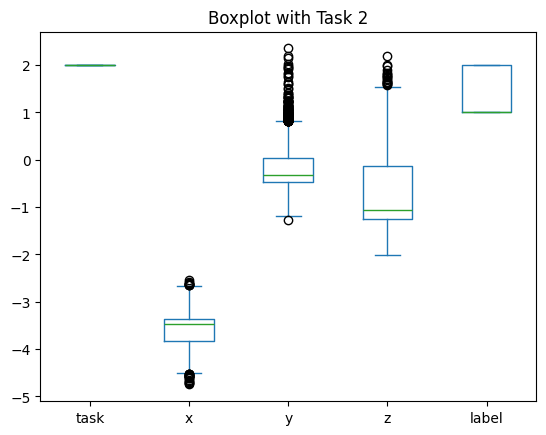

In [ ]:
plt.figure(figsize=(12,6))
df2.plot.box(title='Boxplot with Task 2')
plt.show()

<Figure size 1200x600 with 0 Axes>

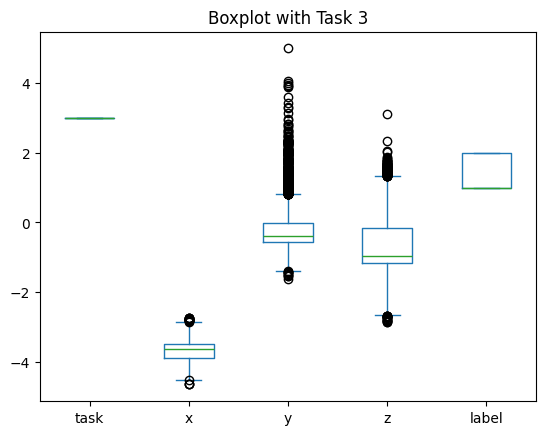

In [ ]:
plt.figure(figsize=(12,6))
df3.plot.box(title='Boxplot with Task 3')
plt.show()

In [ ]:
def cap_outliers_iqr(df, columns):
    df_capped = df.copy()
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Cap the values
        df_capped[col] = np.clip(df_capped[col], lower_bound, upper_bound)
    return df_capped


In [ ]:
import numpy as np

df0_capped = cap_outliers_iqr(df0, ['x', 'y', 'z'])
df1_capped = cap_outliers_iqr(df1, ['x', 'y', 'z'])
df2_capped = cap_outliers_iqr(df2, ['x', 'y', 'z'])
df3_capped = cap_outliers_iqr(df3, ['x', 'y', 'z'])

<Figure size 1200x600 with 0 Axes>

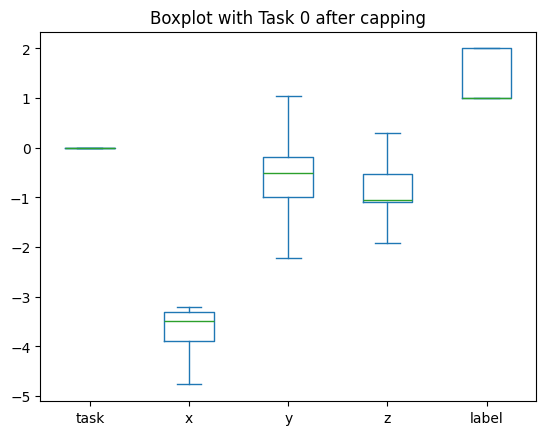

In [ ]:
plt.figure(figsize=(12,6))
df0_capped.plot.box(title='Boxplot with Task 0 after capping')
plt.show()

<Figure size 1200x600 with 0 Axes>

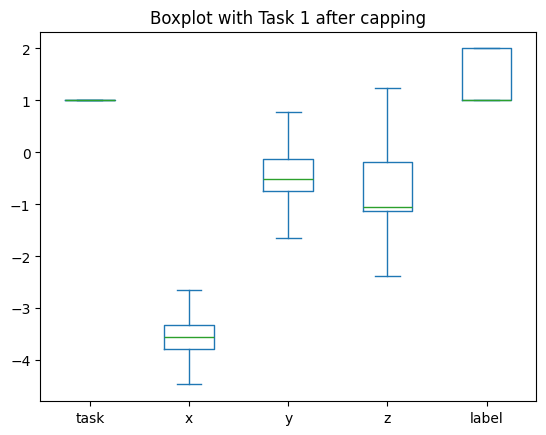

In [ ]:
plt.figure(figsize=(12,6))
df1_capped.plot.box(title='Boxplot with Task 1 after capping')
plt.show()

<Figure size 1200x600 with 0 Axes>

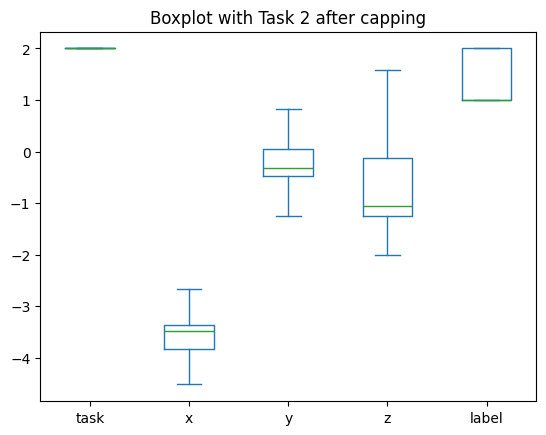

In [ ]:
plt.figure(figsize=(12,6))
df2_capped.plot.box(title='Boxplot with Task 2 after capping')
plt.show()

<Figure size 1200x600 with 0 Axes>

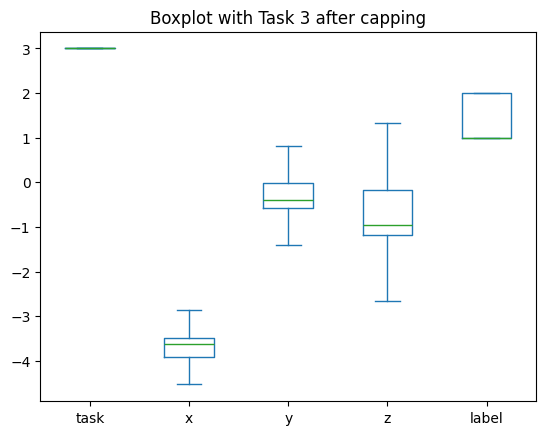

In [ ]:
plt.figure(figsize=(12,6))
df3_capped.plot.box(title='Boxplot with Task 3 after capping')
plt.show()

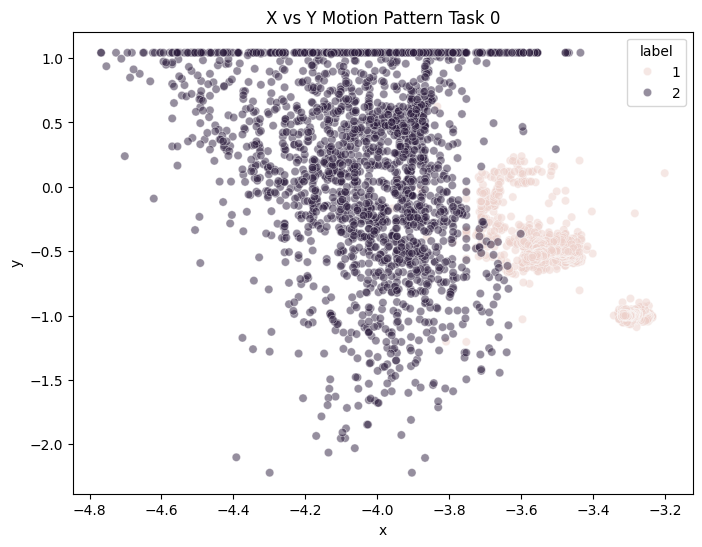

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df0_capped,
    x="x",
    y="y",
    hue="label",
    alpha=0.5
)

plt.title("X vs Y Motion Pattern Task 0")
plt.show()

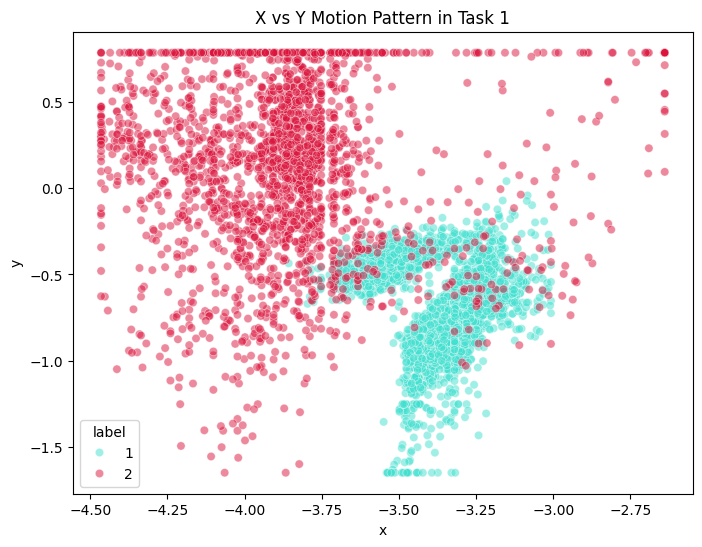

In [ ]:
plt.figure(figsize=(8,6))
custom_colors = ['turquoise', 'crimson']
sns.scatterplot(
    data=df1_capped,
    x="x",
    y="y",
    hue="label",
    alpha=0.5,
    palette=custom_colors
)

plt.title("X vs Y Motion Pattern in Task 1")
plt.show()

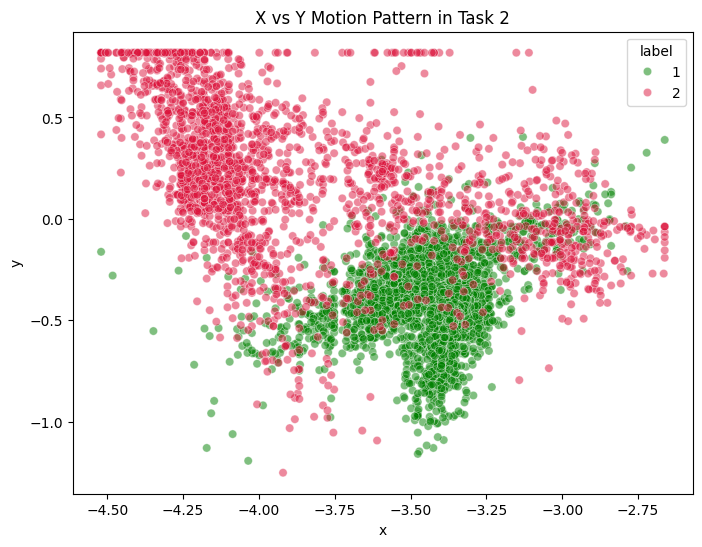

In [ ]:
plt.figure(figsize=(8,6))
custom_colors = ['green', 'crimson']
sns.scatterplot(
    data=df2_capped,
    x="x",
    y="y",
    hue="label",
    alpha=0.5,
    palette=custom_colors
)

plt.title("X vs Y Motion Pattern in Task 2")
plt.show()

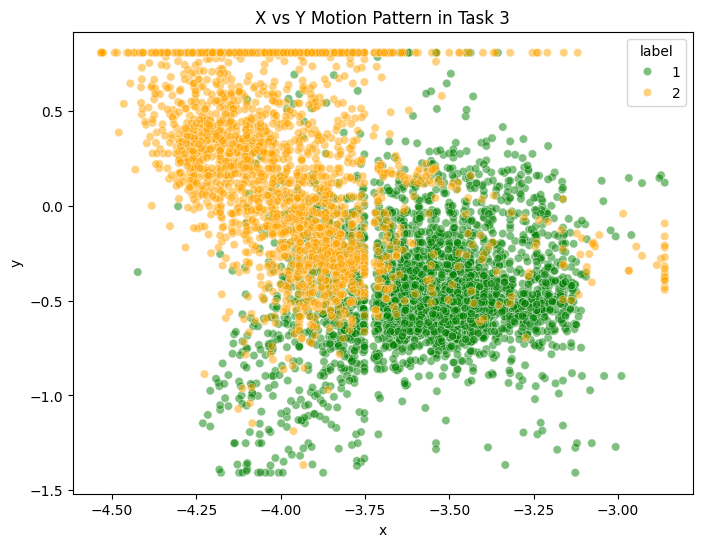

In [ ]:
plt.figure(figsize=(8,6))
custom_colors = ['green', 'orange']
sns.scatterplot(
    data=df3_capped,
    x="x",
    y="y",
    hue="label",
    alpha=0.5,
    palette=custom_colors
)

plt.title("X vs Y Motion Pattern in Task 3")
plt.show()

In [ ]:
df0_capped.label.value_counts()

,count
label,
1,4461
2,2215


In [ ]:
df1_capped.label.value_counts()

,count
label,
1,4337
2,2338


In [ ]:
df2_capped.label.value_counts()

,count
label,
1,4196
2,2296


In [ ]:
df3_capped.label.value_counts()

,count
label,
1,4537
2,2258


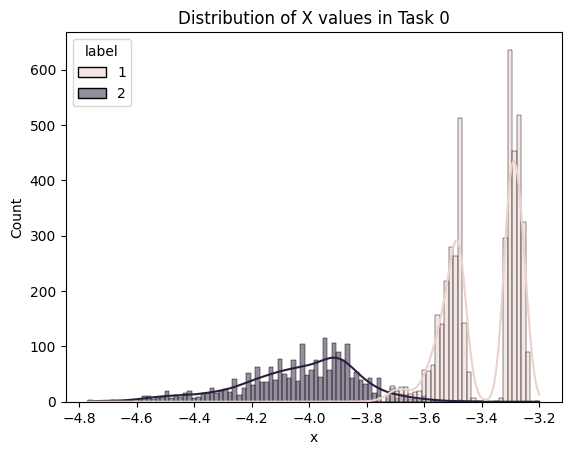

<Figure size 800x600 with 0 Axes>

In [ ]:

sns.histplot(data=df0_capped, x="x", hue="label", kde=True, bins=100)
plt.title("Distribution of X values in Task 0")
plt.figure(figsize=(8,6))
plt.show()

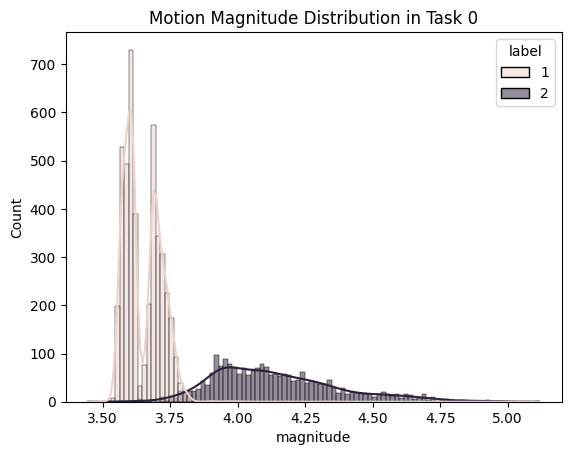

In [ ]:
df0_capped["magnitude"] = (df0_capped["x"]**2 + df0_capped["y"]**2 + df0_capped["z"]**2) ** 0.5
sns.histplot(data=df0_capped, x="magnitude", hue="label", kde=True, bins=100)
plt.title("Motion Magnitude Distribution in Task 0")
plt.show()


In [ ]:
df0_capped.head(5)

,task,x,y,z,label,magnitude
12343,0,-3.5397,-0.5922,-1.0195,1,3.730892
12344,0,-3.5299,-0.4847,-0.9976,1,3.700045
12345,0,-3.5226,-0.5238,-1.0391,1,3.709826
12346,0,-3.5031,-0.5531,-1.0269,1,3.692175
12347,0,-3.5006,-0.6166,-1.0904,1,3.717979


In [ ]:
df0_capped["magnitude"] = (df0_capped["x"]**2 + df0_capped["y"]**2 + df0_capped["z"]**2) ** 0.5

In [ ]:
df0_capped["magnitude"]

,magnitude
12343,3.730892
12344,3.700045
12345,3.709826
12346,3.692175
12347,3.717979
...,...
41060,4.073156
41061,4.091824
41062,4.162985
41063,4.275113


In [ ]:
df0_capped.label.value_counts()

,count
label,
1,4461
2,2215


In [ ]:
min_class_size = df0_capped.label.value_counts().min()

In [ ]:
min_class_size

2215

In [ ]:
df0_downsampled = df0_capped.groupby('label', group_keys=False).apply(lambda x: x.sample(n=min_class_size, random_state=42)).reset_index(drop=True)


/tmp/ipykernel_538/27452789.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df0_downsampled = df0_capped.groupby('label', group_keys=False).apply(lambda x: x.sample(n=min_class_size, random_state=42)).reset_index(drop=True)


In [ ]:
df0_downsampled['label'].value_counts()

,count
label,
1,2215
2,2215


In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

labels = df0_downsampled["label"]
#df0_capped["magnitude"] = (df0_capped["x"]**2 + df0_capped["y"]**2 + df0_capped["z"]**2) ** 0.5

features = df0_downsampled[["x", "y", "z"]]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.3, random_state=42)


In [ ]:
X_train.shape

(3101, 3)

In [ ]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

In [ ]:
param_grid = {
    'classifier__n_estimators': [100, 250, 500],
    'classifier__max_depth': [1, 3]
}

In [ ]:
param_grid = {
    'svm__C': [0.001, 0.01, 0.1, 1],
    'svm__gamma': [10, 1, 0.1, 0.01],
    'svm__kernel': ['rbf']
}

In [ ]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    verbose=1,
    n_jobs=-1
)

In [ ]:
grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC())]),
             n_jobs=-1,
             param_grid={'svm__C': [0.001, 0.01, 0.1, 1],
                         'svm__gamma': [10, 1, 0.1, 0.01],
                         'svm__kernel': ['rbf']},
             scoring='accuracy', verbose=1)

In [ ]:
print(f"Best parameters found: {grid_search.best_params_}")
print(f"Best cross-validation '{grid_search.scoring}' score: {grid_search.best_score_}")

Best parameters found: {'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'rbf'}
Best cross-validation 'accuracy' score: 0.9932276774875279


In [ ]:
best_pipeline = grid_search.best_estimator_
y_pred = best_pipeline.predict(X_test)

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.99      0.99      0.99       693
           2       0.99      0.99      0.99       636

    accuracy                           0.99      1329
   macro avg       0.99      0.99      0.99      1329
weighted avg       0.99      0.99      0.99      1329



In [ ]:
# Create magnitude feature
df1_capped["magnitude"] = (df1_capped["x"]**2 + df1_capped["y"]**2 + df1_capped["z"]**2) ** 0.5

# Balance dataset
min_class_size = df1_capped.label.value_counts().min()

df1_downsampled = df1_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

# Prepare features and labels
labels = df1_downsampled["label"]
features = df1_downsampled[["x","y","z"]]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

# Train model
grid_search.fit(X_train, y_train)

best_pipeline_task1 = grid_search.best_estimator_

# Predictions
y_pred = best_pipeline_task1.predict(X_test)

print("Task 1 Results")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 16 candidates, totalling 48 fits


/tmp/ipykernel_538/1067949765.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Task 1 Results
              precision    recall  f1-score   support

           1       0.99      1.00      0.99       702
           2       1.00      0.99      0.99       701

    accuracy                           0.99      1403
   macro avg       0.99      0.99      0.99      1403
weighted avg       0.99      0.99      0.99      1403



In [ ]:
df2_capped["magnitude"] = (df2_capped["x"]**2 + df2_capped["y"]**2 + df2_capped["z"]**2) ** 0.5

min_class_size = df2_capped.label.value_counts().min()

df2_downsampled = df2_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

labels = df2_downsampled["label"]
features = df2_downsampled[["x","y","z"]]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

grid_search.fit(X_train, y_train)

best_pipeline_task2 = grid_search.best_estimator_

y_pred = best_pipeline_task2.predict(X_test)

print("Task 2 Results")
print(classification_report(y_test, y_pred))

/tmp/ipykernel_538/1029446466.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Task 2 Results
              precision    recall  f1-score   support

           1       1.00      0.98      0.99       721
           2       0.98      1.00      0.99       657

    accuracy                           0.99      1378
   macro avg       0.99      0.99      0.99      1378
weighted avg       0.99      0.99      0.99      1378



In [ ]:
df3_capped["magnitude"] = (df3_capped["x"]**2 + df3_capped["y"]**2 + df3_capped["z"]**2) ** 0.5

min_class_size = df3_capped.label.value_counts().min()

df3_downsampled = df3_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

labels = df3_downsampled["label"]
features = df3_downsampled[["x","y","z"]]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

grid_search.fit(X_train, y_train)

best_pipeline_task3 = grid_search.best_estimator_

y_pred = best_pipeline_task3.predict(X_test)

print("Task 3 Results")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 16 candidates, totalling 48 fits


/tmp/ipykernel_538/3520491950.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Task 3 Results
              precision    recall  f1-score   support

           1       0.98      0.99      0.99       705
           2       0.99      0.98      0.99       650

    accuracy                           0.99      1355
   macro avg       0.99      0.99      0.99      1355
weighted avg       0.99      0.99      0.99      1355



In [ ]:
import joblib

joblib.dump(best_pipeline, "task0_model.pkl")
joblib.dump(best_pipeline_task1, "task1_model.pkl")
joblib.dump(best_pipeline_task2, "task2_model.pkl")
joblib.dump(best_pipeline_task3, "task3_model.pkl")

['task3_model.pkl']

# magnitude only model

In [ ]:
# Create magnitude feature
df0_capped["magnitude"] = (df0_capped["x"]**2 + df0_capped["y"]**2 + df0_capped["z"]**2) ** 0.5

# Balance dataset
min_class_size = df0_capped.label.value_counts().min()

df0_downsampled = df0_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

# Prepare features and labels
labels = df0_downsampled["label"]
features = df0_downsampled[["magnitude"]]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

# Train model
grid_search.fit(X_train, y_train)

best_pipeline_task0 = grid_search.best_estimator_

# Predictions
y_pred = best_pipeline_task0.predict(X_test)

print("Task 0 Results")
print(classification_report(y_test, y_pred))

/tmp/ipykernel_538/1122066965.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Task 0 Results
              precision    recall  f1-score   support

           1       0.95      0.99      0.97       693
           2       0.99      0.94      0.97       636

    accuracy                           0.97      1329
   macro avg       0.97      0.97      0.97      1329
weighted avg       0.97      0.97      0.97      1329



In [ ]:
df1_capped["magnitude"] = (df1_capped["x"]**2 + df1_capped["y"]**2 + df1_capped["z"]**2) ** 0.5

min_class_size = df1_capped.label.value_counts().min()

df1_downsampled = df1_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

labels = df1_downsampled["label"]
features = df1_downsampled[["magnitude"]]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

grid_search.fit(X_train, y_train)

best_pipeline_task1 = grid_search.best_estimator_

y_pred = best_pipeline_task1.predict(X_test)

print("Task 1 Results")
print(classification_report(y_test, y_pred))

/tmp/ipykernel_538/3813191651.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Task 1 Results
              precision    recall  f1-score   support

           1       0.78      0.83      0.80       702
           2       0.82      0.76      0.79       701

    accuracy                           0.80      1403
   macro avg       0.80      0.80      0.80      1403
weighted avg       0.80      0.80      0.80      1403



In [ ]:
df2_capped["magnitude"] = (df2_capped["x"]**2 + df2_capped["y"]**2 + df2_capped["z"]**2) ** 0.5

min_class_size = df2_capped.label.value_counts().min()

df2_downsampled = df2_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

labels = df2_downsampled["label"]
features = df2_downsampled[["magnitude"]]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

grid_search.fit(X_train, y_train)

best_pipeline_task2 = grid_search.best_estimator_

y_pred = best_pipeline_task2.predict(X_test)

print("Task 2 Results")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 16 candidates, totalling 48 fits


/tmp/ipykernel_538/4084709078.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Task 2 Results
              precision    recall  f1-score   support

           1       0.84      0.86      0.85       721
           2       0.84      0.83      0.83       657

    accuracy                           0.84      1378
   macro avg       0.84      0.84      0.84      1378
weighted avg       0.84      0.84      0.84      1378



In [ ]:
df3_capped["magnitude"] = (df3_capped["x"]**2 + df3_capped["y"]**2 + df3_capped["z"]**2) ** 0.5

min_class_size = df3_capped.label.value_counts().min()

df3_downsampled = df3_capped.groupby('label', group_keys=False)\
.apply(lambda x: x.sample(n=min_class_size, random_state=42))\
.reset_index(drop=True)

labels = df3_downsampled["label"]
features = df3_downsampled[["magnitude"]]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=42
)

grid_search.fit(X_train, y_train)

best_pipeline_task3 = grid_search.best_estimator_

y_pred = best_pipeline_task3.predict(X_test)

print("Task 3 Results")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 16 candidates, totalling 48 fits


/tmp/ipykernel_538/3501705939.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min_class_size, random_state=42))\


Task 3 Results
              precision    recall  f1-score   support

           1       0.80      0.75      0.77       705
           2       0.75      0.79      0.77       650

    accuracy                           0.77      1355
   macro avg       0.77      0.77      0.77      1355
weighted avg       0.77      0.77      0.77      1355



In [ ]:
import joblib

joblib.dump(best_pipeline_task0, "task0_magnitude_model.pkl")
joblib.dump(best_pipeline_task1, "task1_magnitude_model.pkl")
joblib.dump(best_pipeline_task2, "task2_magnitude_model.pkl")
joblib.dump(best_pipeline_task3, "task3_magnitude_model.pkl")

['task3_magnitude_model.pkl']

In [ ]:
from google.colab import files

files.download("task0_magnitude_model.pkl")
files.download("task1_magnitude_model.pkl")
files.download("task2_magnitude_model.pkl")
files.download("task3_magnitude_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>